# Interacting with Web APIs – Part 1

We are running through the core ideas of web APIs and hands-on practice calling one from the terminal and from Python. We are using the free **MyMemory Translation API** as a live example.

### Main Sections
1. What an API is.
2. Calling an API from the terminal.
3. Interacting with an API in a program.

## 1. What is an API?

**API** stands for **Application Programming Interface**. It is a set of rules and protocols that lets one piece of software talk to another.

Think of an API like a **waiter in a restaurant**:
- You place an order (a **request**).
- The waiter brings your food (a **response**).
- You don't need to know how the kitchen works.

APIs are how modern software opens up its data and features to other software. Examples you may already have used:
- A **"Sign in with Google"** button on a website. That is an API.
- A **flight booking site** asking an airline for available flights and prices.
- **Payment systems** that charge a card on behalf of a shop.

Internal APIs also exist. Large teams often split an application into several services that talk to each other through APIs.

**Food for thought:** Is there any API you have used, even without realising it?

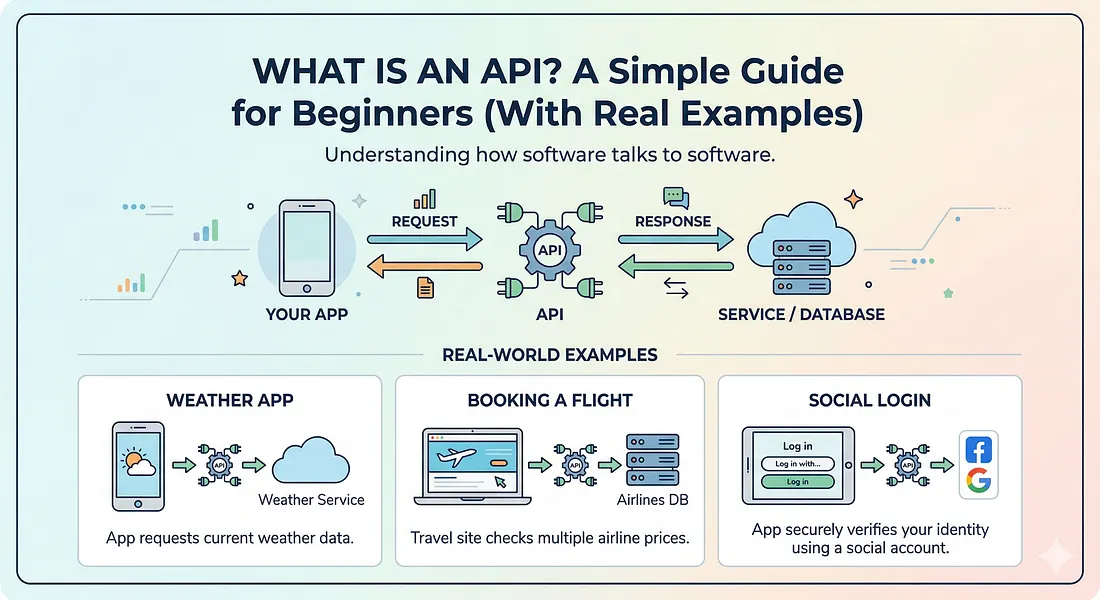
https://pub.towardsai.net/what-is-an-api-a-simple-guide-for-beginners-with-real-examples-16b3be032d1f

## 2. Requests and responses

An API conversation has two parts:

| Part | Example |
|---|---|
| **Request** | "What is the weather in London?" |
| **Response** | "The weather is 18°C and partly cloudy." |

The application making the request does not need to know how the answer is calculated. It just gets the answer.

An API is like a **contract**: when one side sends a request in a specific format, the other side replies in a specific format.

## 3. JSON: the language APIs speak

Most web APIs return data in **JSON** (**J**ava**S**cript **O**bject **N**otation) format. It is lightweight, easy for people to read, and easy for programs to work with.

JSON stores data as **key-value pairs**. Rules to remember:
- Keys are always in **double quotes**.
- Values can be a number, text, `true`/`false`, a list, or another JSON object. These are JSON Data Types.

### Summary of JSON Data Types

| Data Type | Category | Description & Rules | Example |
| :--- | :--- | :--- | :--- |
| **String** | Primitive | Text enclosed in double quotes (`"`). Single quotes are invalid. | `"Hello, world!"` |
| **Number** | Primitive | Base-10 integers or floating-point numbers (supports scientific notation). | `42`, `3.14`, `-10`, `2.5e-1` |
| **Boolean** | Primitive | Lowercase `true` or `false` without quotes. | `true` |
| **Null** | Primitive | Lowercase `null` representing an empty or missing value. | `null` |
| **Object** | Container | Unordered key-value pairs in curly braces `{}`. Keys must be double-quoted strings. | `{"id": 1, "active": true}` |
| **Array** | Container | Ordered list of comma-separated values (any JSON type) in square brackets `[]`. | `["apple", 10, false, null]` |


**Note:**
* Primitive <-> Atomic
* Container <-> Compound

In [10]:
person_json = '''
{
  "name": "Aisha",
  "age": 25,
  "isStudent": true,
  "hobbies": ["reading", "swimming"]
}
'''

print(person_json)


{
  "name": "Aisha",
  "age": 25,
  "isStudent": true,
  "hobbies": ["reading", "swimming"]
}



In [ ]:
# Method 1
 
person_json = '''

{

  "name": "Aisha",

  "age": 25,

  "isStudent": true,

  "hobbies":['swimming', 'running', 'reading']

}

'''
 
print(person_json)
 
 
 
# Method 2
 
person_json = '''

{

  "name": "Aisha",

  "age": 25,

  "isStudent": true

}

'''
 
# 1. Parse (to Python dictionary) 

data = json.loads(person_json)
 
# 2. Modify

data["hobbies"] = ['swimming', 'running']
 
# 3. Convert back

person_json = json.dumps(data) 

person_json
 



{

  "name": "Aisha",

  "age": 25,

  "isStudent": true,

  "hobbies":['swimming', 'running']

}




'{"name": "Aisha", "age": 25, "isStudent": true, "hobbies": ["swimming", "running"]}'

Python can convert JSON text into a dictionary with `json.loads()`.   
Notice how `true` becomes `True`. JSON is a built-in Python library, like math.  
JSON library encodes Python objects into JSON strings and decodes JSON strings back into Python dictionaries and lists

In [2]:
import json

person = json.loads(person_json)

print(type(person))       # <class 'dict'>
print(person["name"])     # Aisha
print(person["isStudent"])

<class 'dict'>
Aisha
True


In [3]:
person

{'name': 'Aisha', 'age': 25, 'isStudent': True}

### Try it: nested JSON

Real API responses often nest objects and lists inside each other. Run this cell, then read the output and predict what each line will print before you check.

In [4]:
weather_json = '''
{
  "city": "London",
  "current": {
    "temperature_c": 18,
    "conditions": "partly cloudy"
  },
  "forecast": ["rain", "sunny", "cloudy"]
}
'''

weather_json

'\n{\n  "city": "London",\n  "current": {\n    "temperature_c": 18,\n    "conditions": "partly cloudy"\n  },\n  "forecast": ["rain", "sunny", "cloudy"]\n}\n'

In [5]:
print(weather_json)


{
  "city": "London",
  "current": {
    "temperature_c": 18,
    "conditions": "partly cloudy"
  },
  "forecast": ["rain", "sunny", "cloudy"]
}



In [6]:
type(weather_json)

str

In [7]:
weather = json.loads(weather_json)
weather

{'city': 'London',
 'current': {'temperature_c': 18, 'conditions': 'partly cloudy'},
 'forecast': ['rain', 'sunny', 'cloudy']}

In [8]:
print(weather)

{'city': 'London', 'current': {'temperature_c': 18, 'conditions': 'partly cloudy'}, 'forecast': ['rain', 'sunny', 'cloudy']}


In [9]:
type(weather)

dict

**Recap**:
* weather_json:
    * a string containing JSON-formatted text.
* weather:
    * a dictionary built from that text

In [ ]:
weather

In [ ]:
weather["current"]

In [ ]:
weather["current"]["temperature_c"]

In [ ]:
weather["forecast"]

In [ ]:
weather["forecast"][1]

In [ ]:
len(weather["forecast"])

**Exercise:** Add a `"hobbies"` list with two items to the `person` JSON above, then print the second hobby.

In [ ]:
person_json = '''
{
  "name": "Aisha",
  "age": 25,
  "isStudent": true
}
'''

print(person_json)

## 4. SOAP vs REST

There are two popular styles of web API on the internet today.

| | **SOAP** (Simple Object Access Protocol) | **REST** (Representational State Transfer) |
|---|---|---|
| **What it is** | A strict protocol with rigid rules | A set of design principles, not strictly enforced |
| **Data format** | XML (similar to HTML) | Usually JSON |
| **Typical use** | Older or more formal systems | Modern web development |
| **Feel** | More rigid | Lighter and easier to work with |

In this session we focus on **RESTful** APIs because they are common in modern development and simpler to use. A RESTful API follows the REST principles.

## 5. Using an API with Python

We can use the **`requests`** (https://requests.readthedocs.io/en/latest/) library *inside Python* to let our programs fetch data from the internet and work with it.

If `requests` is not installed, run `%pip install requests` in a cell first.

https://requests.readthedocs.io/en/latest/api/

In [12]:
%pip install requests

Note: you may need to restart the kernel to use updated packages.


Using the **requests** library, the get() method sends a GET request to the specified url.
Syntax: 
```python
requests.get(url, params={key: value}, args)
```
https://www.w3schools.com/python/ref_requests_get.asp

Using this https://mymemory.translated.net/doc/spec.php for illustration:   
 


Call example:
```
https://api.mymemory.translated.net/get?q=Hello World!&langpair=en|it 
```

#### Breaking down the MyMemory URL

```
https://api.mymemory.translated.net/get?q=Hello World!&langpair=en|it
```

| Part | Meaning |
|-----|-----|
| `https://api.mymemory.translated.net` | The **server** (the host) |
| `/get` | The **endpoint**, the action the server should perform |
| `?` | Starts the **query string**, where the parameters go |
| `q=Hello World!` | Parameter: the **text** to translate |
| `&` | Separates one parameter from the next |
| `langpair=en\|it` | Parameter: the **language pair**, English to Italian |

##### What is `?`

`?` marks the end of the path and the start of the parameters. Everything after it is data sent to the server.

##### What is `q`?

`q` is the **name of a parameter**. The API designers chose it, and it stands for "query," meaning the text to translate. You could not rename it. The server only understands the names it documents.

##### How do we know?

Read the API's documentation. The lesson points to the MyMemory spec page:

- https://mymemory.translated.net/doc/spec.php

That page lists each parameter, what it means, and whether it's required. Look for `q` (the text) and `langpair` (the language direction, such as `en|it`).

##### What is `&`?

`&` separates parameters. Each parameter takes the form `name=value`, and `&` joins them:

```
q=Hello World!  &  langpair=en|it
```

If you had a third parameter, you would add another `&`.

In Python, you don't write any of this yourself. `requests` builds the query string from a dictionary and encodes the spaces and symbols:

```python
requests.get(
    "https://api.mymemory.translated.net/get",
    params={"q": "Hello World!", "langpair": "en|it"},
    timeout=10,
)
```

In [13]:
import requests

response = requests.get(
    "https://api.mymemory.translated.net/get",
    params={"q": "Hello world!", "langpair": "en|es"}
)

response

<Response [200]>

**<Response [200]>** is the string representation of a successful HTTP response object, most commonly seen when using the Python requests library. It indicates that the server received, understood, and successfully processed your request (HTTP status code 200 OK).  
https://en.wikipedia.org/wiki/List_of_HTTP_status_codes

In [14]:
type(response)

requests.models.Response

In [15]:
# Builtin JSON decoder
# Parse a JSON response body from an HTTP request directly into a native Python dictionary or list.
data = response.json()
data

{'responseData': {'translatedText': '"Hola a todos"', 'match': 1},
 'quotaFinished': False,
 'mtLangSupported': None,
 'responseDetails': '',
 'responseStatus': 200,
 'responderId': None,
 'exception_code': None,
 'matches': [{'id': '437829924563374815',
   'segment': 'Hello world!',
   'translation': '"Hola a todos"',
   'source': 'en-GB',
   'target': 'es-ES',
   'quality': 74,
   'reference': None,
   'usage-count': 5,
   'subject': '',
   'created-by': 'MateCat',
   'last-updated-by': 'MateCat',
   'create-date': '2024-02-05 14:47:31',
   'last-update-date': '2024-02-05 14:47:31',
   'match': 1,
   'penalty': 0},
  {'id': '585658178',
   'segment': 'Hello world!',
   'translation': '¡Hola mundo!',
   'source': 'en-GB',
   'target': 'es-ES',
   'quality': '0',
   'reference': None,
   'usage-count': 2,
   'subject': 'All',
   'created-by': 'Public_Corpora',
   'last-updated-by': 'Public_Corpora',
   'create-date': '2018-02-13 12:20:04',
   'last-update-date': '2018-02-13 12:20:04',


In [16]:
type(data)

dict

In [6]:
print(data["responseData"]["translatedText"])

"Hola a todos"


In [7]:
# https://realpython.com/ref/stdlib/pprint/
from pprint import pp

pp(data)

{'responseData': {'translatedText': '"Hola a todos"', 'match': 1},
 'quotaFinished': False,
 'mtLangSupported': None,
 'responseDetails': '',
 'responseStatus': 200,
 'responderId': None,
 'exception_code': None,
 'matches': [{'id': '437829924563374815',
              'segment': 'Hello world!',
              'translation': '"Hola a todos"',
              'source': 'en-GB',
              'target': 'es-ES',
              'quality': 74,
              'reference': None,
              'usage-count': 5,
              'subject': '',
              'created-by': 'MateCat',
              'last-updated-by': 'MateCat',
              'create-date': '2024-02-05 14:47:31',
              'last-update-date': '2024-02-05 14:47:31',
              'match': 1,
              'penalty': 0},
             {'id': '585658178',
              'segment': 'Hello world!',
              'translation': '¡Hola mundo!',
              'source': 'en-GB',
              'target': 'es-ES',
              'quality': '0',
      

### Walking through the code

| Line | What it does |
|---|---|
| `requests.get(...)` | Sends a **GET** request (a request to *read* data) to the translation API. |
| `params={...}` | Tells the API what text to translate and in which direction. `requests` builds the full URL for you. |
| `response.json()` | Converts the API's reply from JSON text into a Python dictionary. |
| `data["responseData"]["translatedText"]` | Digs into the nested dictionary to pull out the translated text. |

Next, look at the request URL that `requests` built, the status code, and the full structure of the response.

In [8]:
import json
import requests

response = requests.get(
    "https://api.mymemory.translated.net/get",
    params={"q": "Hello world!", "langpair": "en|es"}
)

print("Status code:", response.status_code)   # 200 means success

Status code: 200


In [9]:
print("URL sent:   ", response.url)           # shows how the parameters were encoded

URL sent:    https://api.mymemory.translated.net/get?q=Hello+world%21&langpair=en%7Ces


## 6. Experimenting: a reusable function

Once you can make one call, wrap it in a function so you can reuse it with any text and any language pair.

In [17]:
import requests

def translate(text, source="en", target="es"):
    """Translate text using the MyMemory API and return the translated string."""
    response = requests.get(
        "https://api.mymemory.translated.net/get",
        params={"q": text, "langpair": f"{source}|{target}"},
        timeout=10,
    )
    return response.json()["responseData"]["translatedText"]

print(translate("Hello world!"))                 # English -> Spanish (default)
print(translate("Good morning", "en", "fr"))     # English -> French

"Hola a todos"
Bonjour


**Exercise:** Translate the same phrase into several languages with a loop.

In [18]:
phrase = "Hello world!"
languages = [("es", "Spanish"), ("fr", "French"), ("de", "German"), ("it", "Italian")]

for code, name in languages:
    print(f"{name} -> {translate(phrase, 'en', code)}")

Spanish -> "Hola a todos"
French -> Bonjour tout le monde!
German -> Hallo Welt!
Italian -> Ciao mondo!


**Exercise (your turn):** Write your own phrase and translate it to a language of your choice. Then change the **source** language and translate back to English. Does the round trip give you back the original?

In [19]:
# Purpose : Translate a phrase to another language, then translate it back to English
# Input   : an English phrase and a target language code
# Output  : the original, the translation, the back-translation, and whether they match

phrase = "The data pipeline runs every morning."   # your own phrase
target = "ja"                                       # Japanese (try "ms" Malay, "zh" Chinese, "id" Indonesian)

translated = translate(phrase, "en", target)        # step 1: English -> target language
back = translate(translated, target, "en")          # step 2: swap source and target to go back to English

print("Original   :", phrase)
print("Translated :", translated)
print("Back       :", back)
print("Same as original?", back.strip().lower() == phrase.strip().lower())   # ignore case and extra spaces

Original   : The data pipeline runs every morning.
Translated : データパイプラインは毎朝実行されます。
Back       : The data pipeline runs every morning.
Same as original? True


In [20]:
print(translate("早安", "zh", "en"))     # Chinese -> En

good morning


## 8. Knowledge check

Try answering these before you open the answers.

1. **What is an API?**
2. **Why is it important for applications to use APIs?**
3. **Can you name an example of an API you've used in the past?**
4. **What is the difference between SOAP and REST APIs?**
5. **What is a RESTful API?**

<details>
<summary><b>Answers</b></summary>

1. An API (Application Programming Interface) is a set of rules and protocols that lets software components talk to one another.
2. APIs let applications share data and features without knowing how each other works internally. They make it possible to use services such as login, search, and payments without building them from scratch.
3. Any valid example works, such as a Google login button, a weather app, or a flight search.
4. SOAP is a strict protocol that uses XML. REST is a set of flexible design principles that usually uses JSON.
5. A RESTful API is an API that follows the REST principles. These are commonly used in modern web development.

</details>

## 9. Summary

- An **API** is a connection between programs: requests go in, responses come back.
- **REST** APIs usually return **JSON**, which is a set of key-value pairs that is easy to read and parse.
- Python's **`requests`** library is a beginner-friendly way to call APIs from your own code.
- Each time you change the URL or parameters, you ask the API for different data, much like searching for something different in Google.